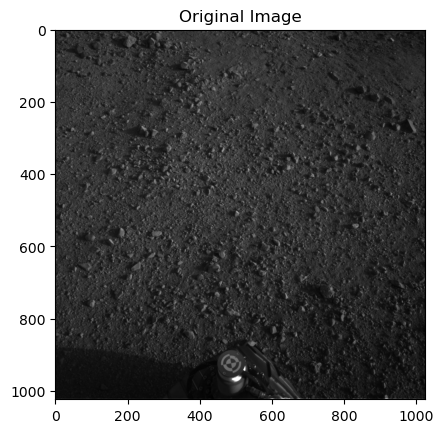

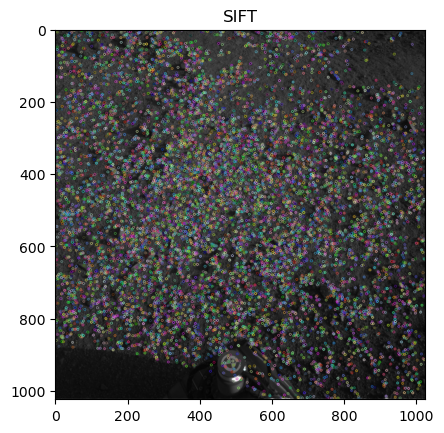

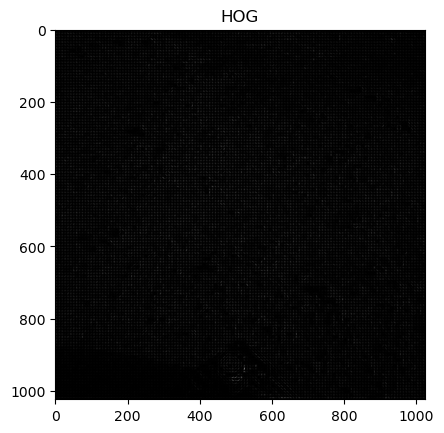

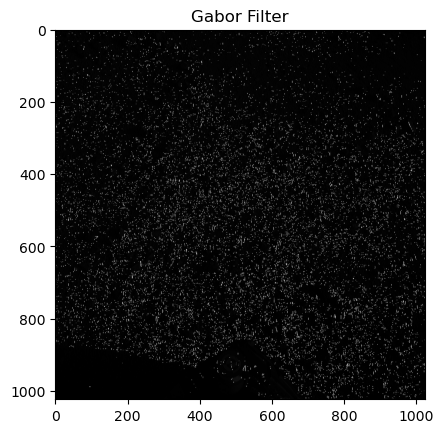

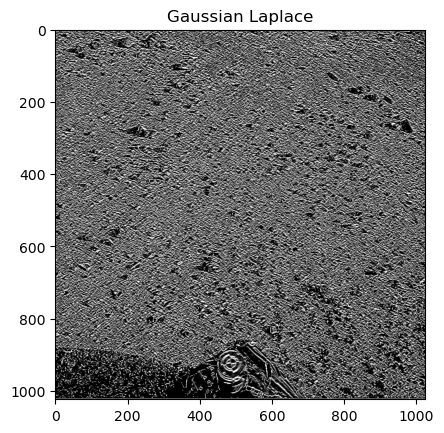

...

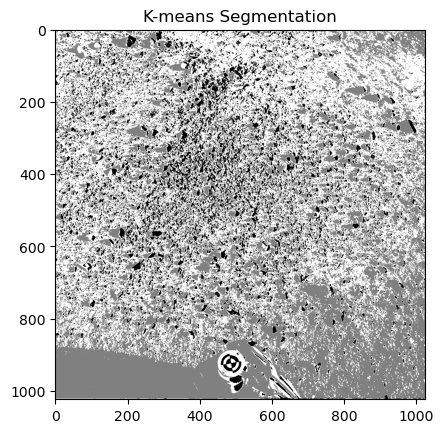

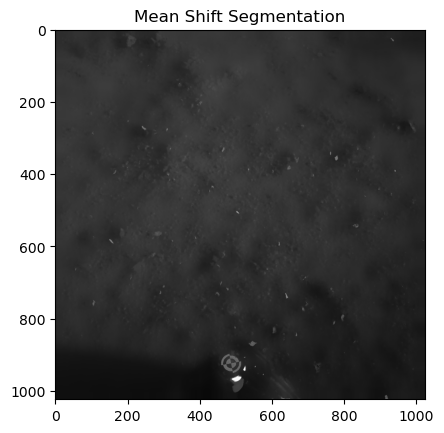

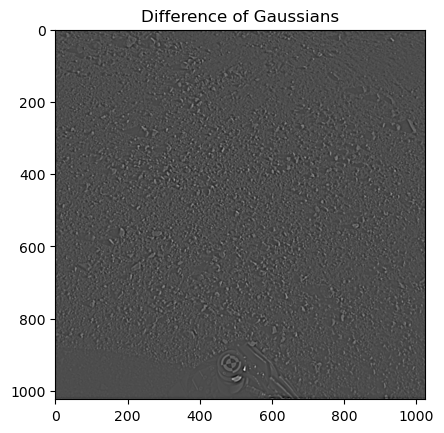

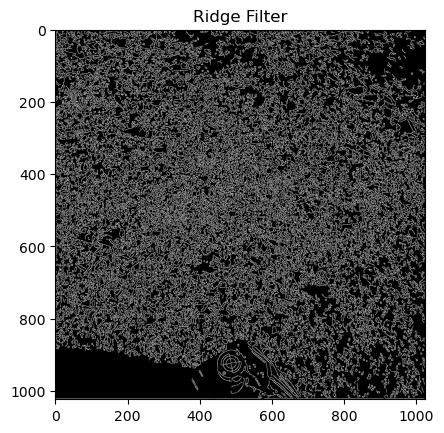

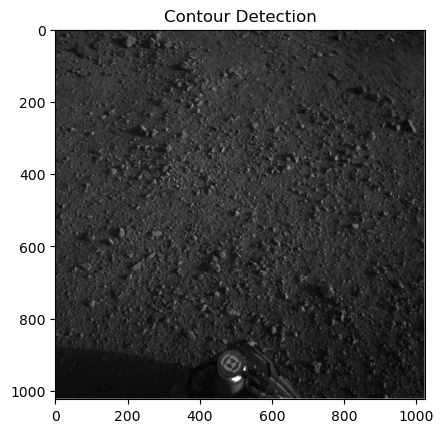

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage.filters import gabor, sobel, prewitt, roberts, gaussian, laplace
from skimage import exposure, measure
from scipy.ndimage import gaussian_laplace
from skimage.restoration import denoise_bilateral
from skimage.segmentation import watershed
from scipy.ndimage import label, distance_transform_edt
from skimage.color import label2rgb
from skimage.morphology import erosion, dilation, opening, closing
from skimage import feature, filters
from scipy import ndimage as ndi

# Load the image
img = cv2.imread('/Users/shashikumarezhil/Downloads/ai4mars-dataset-merged-0.1/msl/images/edr/NLA_397681941EDR_F0020000AUT_04096M1.JPG', cv2.IMREAD_GRAYSCALE)
if img is None:
    print("Error: Image not loaded. Please check the file path.")
else:
    # Display the original image
    plt.imshow(img, cmap='gray')
    plt.title('Original Image')
    plt.show()

    # 1. SIFT
    sift = cv2.SIFT_create()
    keypoints, descriptors = sift.detectAndCompute(img, None)
    img_sift = cv2.drawKeypoints(img, keypoints, None)
    plt.imshow(img_sift, cmap='gray')
    plt.title('SIFT')
    plt.show()

    # 2. HOG (Histogram of Oriented Gradients)
    fd, hog_image = hog(img, visualize=True)
    plt.imshow(hog_image, cmap='gray')
    plt.title('HOG')
    plt.show()

    # 3. Gabor Filter
    gabor_filtered, _ = gabor(img, frequency=0.6)
    plt.imshow(gabor_filtered, cmap='gray')
    plt.title('Gabor Filter')
    plt.show()

    # 4. Gaussian Laplace
    gauss_laplace_img = gaussian_laplace(img, sigma=1)
    plt.imshow(gauss_laplace_img, cmap='gray')
    plt.title('Gaussian Laplace')
    plt.show()

    # 5. Laplace Filter
    laplace_filtered = laplace(img)
    plt.imshow(laplace_filtered, cmap='gray')
    plt.title('Laplace Filter')
    plt.show()

    # 6. Sobel Filter
    sobel_filtered = sobel(img)
    plt.imshow(sobel_filtered, cmap='gray')
    plt.title('Sobel Filter')
    plt.show()

    # 7. Prewitt Filter
    prewitt_filtered = prewitt(img)
    plt.imshow(prewitt_filtered, cmap='gray')
    plt.title('Prewitt Filter')
    plt.show()

    # 8. Roberts Filter
    roberts_filtered = roberts(img)
    plt.imshow(roberts_filtered, cmap='gray')
    plt.title('Roberts Filter')
    plt.show()

    # 9. Bilateral Filter
    img_bilateral = denoise_bilateral(img, sigma_color=0.05, sigma_spatial=15)
    plt.imshow(img_bilateral, cmap='gray')
    plt.title('Bilateral Filter')
    plt.show()

    # 10. Gaussian Blur
    blurred_img = cv2.GaussianBlur(img, (5, 5), 0)
    plt.imshow(blurred_img, cmap='gray')
    plt.title('Gaussian Blur')
    plt.show()

    # 11. Median Filter
    median_filtered = cv2.medianBlur(img, 5)
    plt.imshow(median_filtered, cmap='gray')
    plt.title('Median Filter')
    plt.show()

    # 12. Morphological Dilation
    dilated_img = dilation(img)
    plt.imshow(dilated_img, cmap='gray')
    plt.title('Dilation')
    plt.show()

    # 13. Morphological Erosion
    eroded_img = erosion(img)
    plt.imshow(eroded_img, cmap='gray')
    plt.title('Erosion')
    plt.show()

    # 14. Morphological Opening
    opened_img = opening(img)
    plt.imshow(opened_img, cmap='gray')
    plt.title('Opening')
    plt.show()

    # 15. Morphological Closing
    closed_img = closing(img)
    plt.imshow(closed_img, cmap='gray')
    plt.title('Closing')
    plt.show()

    # 16. Canny Edge Detection
    canny_edges = cv2.Canny(img, 100, 200)
    plt.imshow(canny_edges, cmap='gray')
    plt.title('Canny Edge Detection')
    plt.show()

    # 17. Harris Corner Detection
    harris_corners = cv2.cornerHarris(img, 2, 3, 0.04)
    img_harris = img.copy()
    img_harris[harris_corners > 0.01 * harris_corners.max()] = 255
    plt.imshow(img_harris, cmap='gray')
    plt.title('Harris Corner Detection')
    plt.show()

    # 18. MSER (Maximally Stable Extremal Regions)
    mser = cv2.MSER_create()
    regions, _ = mser.detectRegions(img)
    img_mser = np.copy(img)
    for region in regions:
        hull = cv2.convexHull(np.array(region).reshape(-1, 1, 2))
        cv2.polylines(img_mser, [hull], 1, (255, 0, 0), 1)
    plt.imshow(img_mser, cmap='gray')
    plt.title('MSER Detection')
    plt.show()

    # 19. Gaussian Noise Addition
    noisy_img = img + np.random.normal(0, 25, img.shape)
    plt.imshow(noisy_img, cmap='gray')
    plt.title('Gaussian Noise')
    plt.show()

    # 20. Adaptive Thresholding
    adaptive_thresh = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)
    plt.imshow(adaptive_thresh, cmap='gray')
    plt.title('Adaptive Thresholding')
    plt.show()

    # 21. Otsu’s Thresholding
    _, otsu_thresh = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    plt.imshow(otsu_thresh, cmap='gray')
    plt.title('Otsu Thresholding')
    plt.show()

    # 22. Fourier Transform
    f_transform = np.fft.fft2(img)
    f_transform_shifted = np.fft.fftshift(f_transform)
    magnitude_spectrum = 20 * np.log(np.abs(f_transform_shifted))
    plt.imshow(magnitude_spectrum, cmap='gray')
    plt.title('Fourier Transform')
    plt.show()

    # 23. Histogram Equalization
    equalized_img = cv2.equalizeHist(img)
    plt.imshow(equalized_img, cmap='gray')
    plt.title('Histogram Equalization')
    plt.show()

    # 24. CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    clahe_img = clahe.apply(img)
    plt.imshow(clahe_img, cmap='gray')
    plt.title('CLAHE')
    plt.show()

    # 25. Hough Line Detection
    edges = cv2.Canny(img, 50, 150, apertureSize=3)
    lines = cv2.HoughLines(edges, 1, np.pi / 180, 200)
    img_hough = img.copy()
    if lines is not None:
        for rho, theta in lines[:, 0]:
            a = np.cos(theta)
            b = np.sin(theta)
            x0 = a * rho
            y0 = b * rho
            x1 = int(x0 + 1000 * (-b))
            y1 = int(y0 + 1000 * (a))
            x2 = int(x0 - 1000 * (-b))
            y2 = int(y0 - 1000 * (a))
            cv2.line(img_hough, (x1, y1), (x2, y2), (255, 0, 0), 1)
    plt.imshow(img_hough, cmap='gray')
    plt.title('Hough Line Detection')
    plt.show()

    # 26. Distance Transform
    dist_transform = distance_transform_edt(img)
    plt.imshow(dist_transform, cmap='gray')
    plt.title('Distance Transform')
    plt.show()

    # 27. Watershed Segmentation
    distance = distance_transform_edt(img)
    local_maxi = measure.label(distance)
    labels_ws = watershed(-distance, local_maxi, mask=img)
    label_img = label2rgb(labels_ws, image=img)
    plt.imshow(label_img)
    plt.title('Watershed Segmentation')
    plt.show()

    # 28. Edge Detection with Scharr Filter
    scharr_img = filters.scharr(img)
    plt.imshow(scharr_img, cmap='gray')
    plt.title('Scharr Edge Detection')
    plt.show()

    # 29. Blob Detection
    blobs_log = feature.blob_log(img, max_sigma=30, num_sigma=10, threshold=0.1)
    img_blob = np.copy(img)
    for blob in blobs_log:
        y, x, r = blob
        cv2.circle(img_blob, (int(x), int(y)), int(r), (255, 0, 0), 1)
    plt.imshow(img_blob, cmap='gray')
    plt.title('Blob Detection')
    plt.show()

    # 30. Denoising with Median Filter
    img_denoised = filters.median(img)
    plt.imshow(img_denoised, cmap='gray')
    plt.title('Denoising with Median Filter')
    plt.show()

    # 31. Laplacian of Gaussian (LoG)
    img_log = gaussian_laplace(img, sigma=1)
    plt.imshow(img_log, cmap='gray')
    plt.title('Laplacian of Gaussian')
    plt.show()

    # 32. Connected Components
    num_labels, labels_img = cv2.connectedComponents(img)
    plt.imshow(labels_img, cmap='nipy_spectral')
    plt.title(f'Connected Components: {num_labels} components')
    plt.show()

    # 33. Hough Circle Detection
    img_circles = cv2.medianBlur(img, 5)
    circles = cv2.HoughCircles(img_circles, cv2.HOUGH_GRADIENT, dp=1.2, minDist=30, param1=50, param2=30, minRadius=1, maxRadius=30)
    img_hough_circles = np.copy(img)
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0, :]:
            cv2.circle(img_hough_circles, (i[0], i[1]), i[2], (255, 0, 0), 1)
    plt.imshow(img_hough_circles, cmap='gray')
    plt.title('Hough Circle Detection')
    plt.show()

    # 34. Skeletonization
    skeleton = feature.canny(img)
    plt.imshow(skeleton, cmap='gray')
    plt.title('Skeletonization')
    plt.show()

    # 35. Image Segmentation using K-means
    img_flat = img.reshape((-1, 1))
    img_flat = np.float32(img_flat)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
    k = 3
    _, labels, centers = cv2.kmeans(img_flat, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    segmented_img = labels.reshape(img.shape)
    plt.imshow(segmented_img, cmap='gray')
    plt.title('K-means Segmentation')
    plt.show()

    # 36. Mean Shift Segmentation
    img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    img_mean_shift = cv2.pyrMeanShiftFiltering(img_bgr, 21, 51)
    plt.imshow(cv2.cvtColor(img_mean_shift, cv2.COLOR_BGR2RGB))
    plt.title('Mean Shift Segmentation')
    plt.show()

    # 37. Edge Detection using Difference of Gaussians (DoG)
    img_gaussian1 = gaussian(img, sigma=1)
    img_gaussian2 = gaussian(img, sigma=3)
    dog = img_gaussian1 - img_gaussian2
    plt.imshow(dog, cmap='gray')
    plt.title('Difference of Gaussians')
    plt.show()

    # 38. Ridge Filter
    ridge_filtered = feature.canny(img)
    plt.imshow(ridge_filtered, cmap='gray')
    plt.title('Ridge Filter')
    plt.show()

    # # 39. Delaunay Triangulation
    # img_delaunay = np.copy(img)
    # points = np.array([[x, y] for y in range(0, img.shape[0], 50) for x in range(0, img.shape[1], 50)])
    # subdiv = cv2.Subdiv2D((0, 0, img.shape[1], img.shape[0]))
    # for p in points:
    #     subdiv.insert(tuple(p))
    # triangles = subdiv.getTriangleList()
    # triangles = np.array(triangles, dtype=np.int32)
    # for t in triangles:
    #     pt1 = (t[0], t[1])
    #     pt2 = (t[2], t[3])
    #     pt3 = (t[4], t[5])
    #     cv2.line(img_delaunay, pt1, pt2, (255, 0, 0), 1)
    #     cv2.line(img_delaunay, pt2, pt3, (255, 0, 0), 1)
    #     cv2.line(img_delaunay, pt3, pt1, (255, 0, 0), 1)
    # plt.imshow(img_delaunay, cmap='gray')
    # plt.title('Delaunay Triangulation')
    # plt.show()

    # 40. Contour Detection
    contours, _ = cv2.findContours(img, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    img_contours = cv2.drawContours(np.copy(img), contours, -1, (255, 0, 0), 1)
    plt.imshow(img_contours, cmap='gray')
    plt.title('Contour Detection')
    plt.show()
